# Tensors, Gradients and Regression

This notebook accompanies the handout of the same name. The setup cell below writes the register.
Nothing has to be downloaded first. The cells run in order from the top.

The register holds 9000 customer records. Its numeric columns are `age`, `income`,
`tenure_months`, `score` and `spend`, the amount each customer spent. `age`, `income` and `score`
have missing values. `split` marks every row as `train` or `test`. The data is synthetic and
generated from a fixed seed. Every number below is therefore reproducible.

In [ ]:
#@title Setup: write register.csv  { display-mode: "form" }
# Writes register.csv, the table every cell below reads: the register with churn, spend and a train/test split.
import base64, csv, gzip, io, os
import numpy as np
import matplotlib.pyplot as plt

_BLOB = (
    "..."
    "2iCCs6uyceRmgYwcca0S6n8AT2LnM8oHAA=="
)

if not os.path.exists("register.csv"):
    with open("register.csv", "wb") as f:
        f.write(gzip.decompress(base64.b64decode(_BLOB)))

print("register.csv:", os.path.getsize("register.csv") // 1024, "KB")

register.csv: 498 KB


In [ ]:
# The imports every cell below assumes, beyond those of the setup cell.
import torch
from torch import nn

## 01 Tensors

A `torch.Tensor` is PyTorch's n-dimensional array: a block of elements of one data type, with a shape. Indexing, slicing, broadcasting, reductions and `@` follow the same rules as on a NumPy array. A tensor differs from an array in the default dtype, in the names of two arguments, in the device the data is stored on and in the recording of operations for differentiation.

In [ ]:
import torch

t = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])   # from a nested list, like np.array
print(t.shape)
print(t.dtype)

print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.arange(6))
print(torch.rand(2, 3))                 # uniform on [0, 1)

torch.Size([2, 3])
torch.float32
tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([0, 1, 2, 3, 4, 5])
tensor([[0.7031, 0.2744, 0.1025],
        [0.6582, 0.5677, 0.5783]])


`torch.Size` is a subclass of `tuple`. `t.shape[0]` and `len(t.shape)` therefore work as they do on a NumPy shape. The creation functions take the shape as separate integers and also accept a tuple.

### dtype

In [ ]:
a = np.array([1.5, 2.5])                # (2,) float64, NumPy's default

print(torch.tensor([1.5, 2.5]).dtype)                  # PyTorch's default
print(torch.tensor(a).dtype)                           # the array's dtype is kept
print(torch.tensor(a, dtype=torch.float32).dtype)

layer = torch.nn.Linear(2, 1)           # a weighted sum of 2 inputs, with float32 weights
try:
    layer(torch.tensor(a))
except RuntimeError as err:
    print("RuntimeError:", err)

torch.float32
torch.float64
torch.float32
RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float


The default floating-point dtype is float64 in NumPy and float32 in PyTorch. A tensor made from a NumPy array keeps the array's float64. Multiplying it with the float32 weights of a layer raises the error above. In the message, `Double` is PyTorch's name for float64. `Float` is its name for float32. Passing `dtype=torch.float32` when the tensor is created avoids the error. `t.float()` converts an existing tensor. float32 takes half the memory of float64.

### Copies and shared memory

In [ ]:
a = np.array([1.5, 2.5])
t = torch.from_numpy(a)                 # shares a's memory
t[0] = 99.0
print(a[0])                             # the array changed too

t2 = torch.tensor(a)                    # a copy
t2[0] = -1.0
print(a[0])                             # unchanged

b = torch.tensor([1.0, 2.0])
nb = b.numpy()                          # shares b's memory
b[0] = 7.0
print(nb[0])

99.0
99.0
7.0


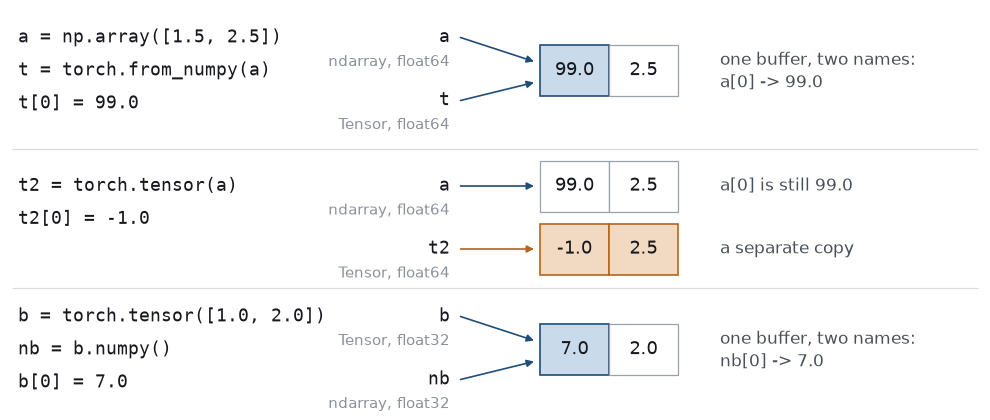

torch.from_numpy(a) and b.numpy() give a second name for the same buffer. The write therefore shows through both names. torch.tensor(a) copies the values into a buffer of its own. Writing to t2 leaves a unchanged.

`torch.from_numpy` and `.numpy()` share memory with the object they are called on, the way a NumPy view shares memory with its base array. A write through one therefore shows in the other. `torch.tensor` always copies. Sharing avoids a copy. It causes errors when one side is modified and the other was expected to stay unchanged. `torch.from_numpy` also keeps the array's dtype. A float64 array therefore still has to be converted.

### Reductions and the matrix product

In [ ]:
x = torch.zeros(5, 4)
print(x[:, 0].shape)                    # an integer index removes an axis
print(x.sum(dim=1).shape)
print(x.mean(dim=0, keepdim=True).shape)
print(x.T.shape)

X = torch.tensor([[47.0, 20.0], [57.0, 19.0], [36.0, 9.0]])    # 3 rows, 2 features
w = torch.tensor([0.5, -1.0])                                   # one weight per feature
print(X @ w)                            # one per row

torch.Size([5])
torch.Size([5])
torch.Size([1, 4])
torch.Size([4, 5])
tensor([3.5000, 9.5000, 9.0000])


PyTorch's names for NumPy's `axis` and `keepdims` are `dim` and `keepdim`. The reductions also accept the NumPy names. The PyTorch documentation and most PyTorch code use `dim` and `keepdim`. `X @ w` multiplies every row of `X` by the weights and adds the products. A layer of a network computes this weighted sum for every row at once.

### Device

In [ ]:
print(torch.cuda.is_available())        # True if PyTorch can use a GPU
device = "cuda" if torch.cuda.is_available() else "cpu"

t = torch.tensor([1.0, 2.0])            # created in main memory
g = t.to(device)                        # a copy in GPU memory when there is a GPU
print(g.device)

if device == "cuda":
    try:
        g + t
    except RuntimeError as err:
        print("RuntimeError:", err)
else:
    print("no GPU: g and t are both in main memory, so g + t runs")

print(g.cpu().numpy())

False
cpu
no GPU: g and t are both in main memory, so g + t runs
[1. 2.]


Every tensor is stored on a device. The device `cpu` is main memory. The device `cuda` is the memory of a GPU. `.to(device)` returns a copy on that device, or the tensor itself if it is already there. An operation between tensors on different devices raises the error above. `.numpy()` works only on a tensor in main memory. A result computed on the GPU therefore goes through `.cpu()` first. Choosing the device once, as in the second line, lets the same code run with or without a GPU. In Colab a GPU is selected under Runtime, then Change runtime type.

## 02 Autograd

Autograd is PyTorch's automatic differentiation. It records every operation on a tensor created with `requires_grad=True`. `backward()` uses that record to compute the derivative of a result with respect to the tensor. We need these derivatives for training, because gradient descent moves every parameter a small step against the derivative of the loss with respect to that parameter.

In [ ]:
x = torch.tensor(5.0, requires_grad=True)

y = 3 * x ** 2 + 4 * x + 2
print(y)
y.backward()                            # dy/dx = 6x + 4, which is 34 at x = 5
print(x.grad)

v = torch.tensor([1.0, 2.0], requires_grad=True)
try:
    (v * 2).backward()                  # two elements, not one
except RuntimeError as err:
    print("RuntimeError:", err)

tensor(97., grad_fn=<AddBackward0>)
tensor(34.)
RuntimeError: grad can be implicitly created only for scalar outputs


`requires_grad=True` marks `x` as a tensor to differentiate with respect to. `backward()` computes the derivative of `y` with respect to every such tensor that `y` was computed from, and stores each derivative in that tensor's `.grad`. Called without arguments, `backward()` needs `y` to hold a single number, such as a loss averaged over the rows. On a tensor with several elements it raises `RuntimeError: grad can be implicitly created only for scalar outputs`.

### The computational graph

In [ ]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(3.0, requires_grad=True)
c = torch.tensor(5.0, requires_grad=True)
d = torch.tensor(10.0, requires_grad=True)

u = a * b                               # 6
v = c * torch.log10(d)                  # 5
e = u + v
print(e)

print(a.is_leaf, u.is_leaf, e.is_leaf)
print(a.grad_fn, u.grad_fn)

tensor(11., grad_fn=<AddBackward0>)
True False False
None <MulBackward0 object at 0x739c2252b0a0>


Autograd records the computation as a directed acyclic graph. The tensors created directly, here `a`, `b`, `c` and `d`, are its **leaves**. Every operation is a node. The final result `e` is the root. A tensor produced by an operation holds the node that produced it in `grad_fn`, named after the operation: `MulBackward0` for a product, `AddBackward0` for a sum. A leaf has no `grad_fn`.

In [ ]:
print(e.grad_fn.next_functions)          # the nodes of u and v
print(v.grad_fn.next_functions)          # c, and log10(d)
print(u.grad_fn._saved_self, u.grad_fn._saved_other)   # a and b, kept from the forward pass

((<MulBackward0 object at 0x739c2252b0a0>, 0), (<MulBackward0 object at 0x739c9492c3d0>, 0))
((<AccumulateGrad object at 0x739b6e710c70>, 0), (<Log10Backward0 object at 0x739b6e710c40>, 0))
tensor(2., requires_grad=True) tensor(3., requires_grad=True)


`next_functions` holds, for each input of a node, the node that produced that input. The recorded graph can therefore be followed from `e` back to the leaves. `c * torch.log10(d)` is two operations. A `Log10Backward0` node therefore sits between `d` and the second `MulBackward0`. An `AccumulateGrad` node stands for a leaf. It adds the gradient that reaches the leaf into the leaf's `.grad`. Each node also keeps the values from the forward pass that its derivative needs. The `MulBackward0` of `u`, for example, holds `a` and `b`.

In [ ]:
e.backward()
print(a.grad, b.grad)                   # de/da = b, de/db = a
print(c.grad)                           # de/dc = log10(d) = 1
print(d.grad)                           # de/dd = c / (d ln 10)
print(u.grad)                           # None, with a warning: u is not a leaf

tensor(3.) tensor(2.)
tensor(1.)
tensor(0.2171)
None


/tmp/ipykernel_1152874/407616453.py:5: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /__w/pytorch/pytorch/build/aten/src/ATen/core/TensorBody.h:493.)
  print(u.grad)                           # None, with a warning: u is not a leaf


### The chain rule

The gradients above follow from the chain rule. Writing `w` for `log10(d)`, the forward pass is four operations: `u = a * b`, `w = log10(d)`, `v = c * w` and `e = u + v`. `e` depends on `d` only along the path d → w → v → e. The chain rule gives the derivative of `e` with respect to `d` as the product of one derivative per operation on that path: de/dd = de/dv × dv/dw × dw/dd.

Each factor is a **local derivative**: the derivative of one operation's output with respect to one of its inputs, with the other inputs held at their values from the forward pass. A node computes its local derivatives from its own inputs alone. With `a = 2`, `b = 3`, `c = 5` and `d = 10`, the forward pass gives u = 6, w = 1 and v = 5. Holding one input of an operation fixed leaves a function of the other input. The local derivative is the derivative of that function:

| operation | held fixed | function of one input | local derivative |
|---|---|---|---|
| `e = u + v` | v = 5 | e = u + 5 | de/du = 1 |
|  | u = 6 | e = 6 + v | de/dv = 1 |
| `u = a * b` | b = 3 | u = 3 × a | du/da = b = 3 |
|  | a = 2 | u = 2 × b | du/db = a = 2 |
| `v = c * w` | w = 1 | v = 1 × c | dv/dc = w = 1 |
|  | c = 5 | v = 5 × w | dv/dw = c = 5 |
| `w = log10(d)` | no other input | w = ln(d) / ln 10 | dw/dd = 1 / (d ln 10) = 0.043429 |

Adding an amount to one input of a sum adds the same amount to the sum. Both local derivatives of `u + v` are therefore 1. A product with one factor held fixed is that factor times the other input. The derivative of k × x with respect to x is k. The local derivative of a product with respect to one factor is therefore the other factor. With `c` held at 5, v = 5 × w and dv/dw = c = 5. For the logarithm, log10(d) = ln(d) / ln 10. The derivative of ln(d) is 1 / d. Together they give dw/dd = 1 / (d ln 10) = 1 / (10 × 2.302585) = 0.043429. The product of the three local derivatives along the path from `d` to `e` is the value of `d.grad` above:

$$
\begin{aligned}
de/dd &= de/dv \times dv/dw \times dw/dd && \text{the chain rule along } d \to w \to v \to e \\
 &= 1 \times c \times 1 / (d \ln 10) && \text{the local derivatives from the table} \\
 &= 1 \times 5 \times 0.043429 && c = 5 \text{ and } d = 10 \\
 &= 0.2171
\end{aligned}
$$

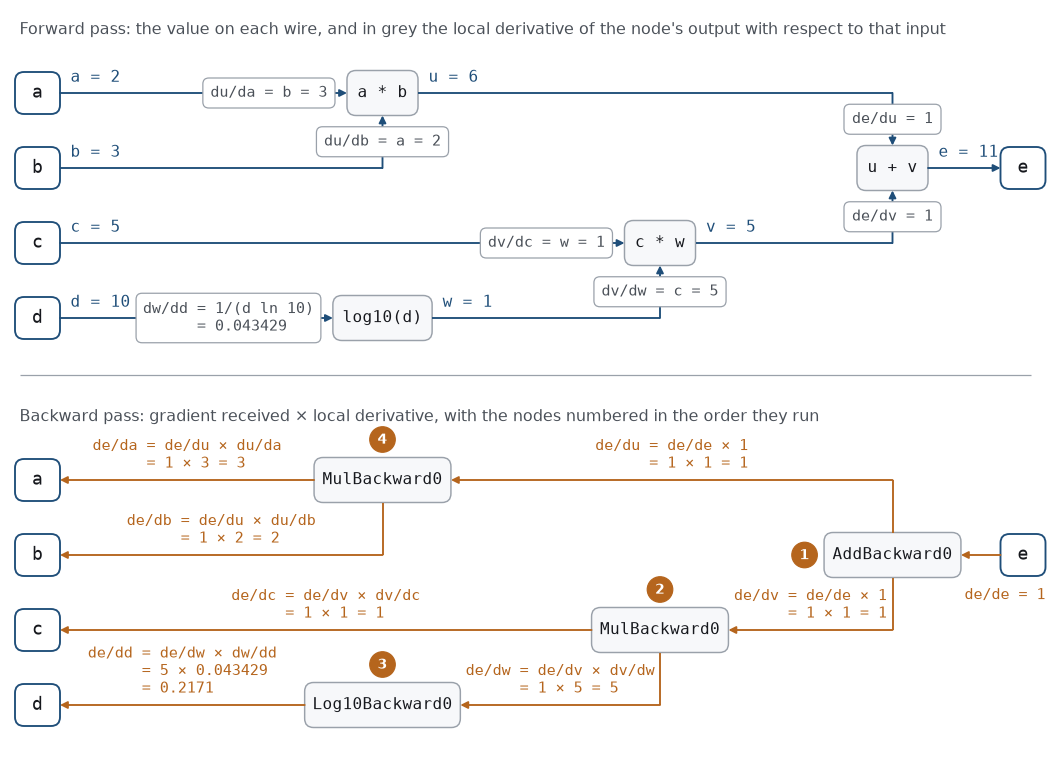

Top: the forward pass, with the value on every wire and, in grey, the local derivative of each node's output with respect to that input. Bottom: the backward pass, with the nodes numbered in the order they run. Every gradient is the gradient its node receives times a local derivative from the top panel, for example de/dw = de/dv × dv/dw = 1 × 5 = 5.

`backward()` computes every gradient in one pass from the root to the leaves. It starts from de/de = 1 at `e`, the derivative of `e` with respect to itself, and runs a node only after every node that uses its output. A node receives the gradient of `e` with respect to its output, multiplies it by its local derivative for each input, and passes each product on to that input. In this graph PyTorch runs the nodes in this order:

1. `AddBackward0` receives de/de = 1. Both of its local derivatives are 1. It passes de/du = de/de × 1 = 1 × 1 = 1 and de/dv = de/de × 1 = 1 × 1 = 1.
1. The `MulBackward0` of `v` receives de/dv = 1 and passes de/dc = de/dv × dv/dc = 1 × 1 = 1 and de/dw = de/dv × dv/dw = 1 × 5 = 5.
1. `Log10Backward0` receives de/dw = 5 and passes de/dd = de/dw × dw/dd = 5 × 0.043429 = 0.2171.
1. The `MulBackward0` of `u` receives de/du = 1 and passes de/da = de/du × du/da = 1 × 3 = 3 and de/db = de/du × du/db = 1 × 2 = 2.

At the root the received gradient is de/de = 1. The gradients that `AddBackward0` passes therefore equal its local derivatives. Steps 2 and 3 evaluate the product de/dv × dv/dw × dw/dd from the left. Step 2 computes de/dw = de/dv × dv/dw = 5. Step 3 multiplies it by dw/dd. Each gradient is computed once and reused by the nodes between it and the leaves, without returning to `e`. The same pass, written out in plain Python, gives the four values of `.grad`:

In [ ]:
import math

a, b, c, d = 2.0, 3.0, 5.0, 10.0       # the same values, as plain floats
w = math.log10(d)                      # 1.0, the forward value of log10(d)

de_de = 1.0                            # the start: e with respect to itself
de_du = de_de * 1.0                    # AddBackward0: de/du = 1
de_dv = de_de * 1.0                    #               de/dv = 1
de_dc = de_dv * w                      # MulBackward0 of v: dv/dc = w
de_dw = de_dv * c                      #                    dv/dw = c
de_dd = de_dw / (d * math.log(10))     # Log10Backward0: dw/dd = 1 / (d ln 10)
de_da = de_du * b                      # MulBackward0 of u: du/da = b
de_db = de_du * a                      #                    du/db = a

print(de_da, de_db, de_dc, round(de_dd, 4))   # the values of a.grad, b.grad, c.grad, d.grad

3.0 2.0 1.0 0.2171


Only the leaves keep their gradient in `.grad`. The gradients of intermediate results are computed in the same pass and then discarded. `retain_grad()` keeps them. They are the values passed between the nodes above:

In [ ]:
a, b, c, d = [torch.tensor(x, requires_grad=True) for x in (2.0, 3.0, 5.0, 10.0)]
u = a * b
w = torch.log10(d)
v = c * w
e = u + v
for t in (u, v, w):
    t.retain_grad()                    # keep the gradient of an intermediate result
e.backward()
print(u.grad, v.grad, w.grad)          # de/du, de/dv, de/dw

tensor(1.) tensor(1.) tensor(5.)


### Gradients along several paths

When a tensor is used more than once, a gradient reaches it along each path. The gradients of all paths are added.

In [ ]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(3.0, requires_grad=True)
f = x * y + x                          # x is used twice
f.backward()
print(x.grad, y.grad)                  # y + 1 and x

tensor(4.) tensor(2.)


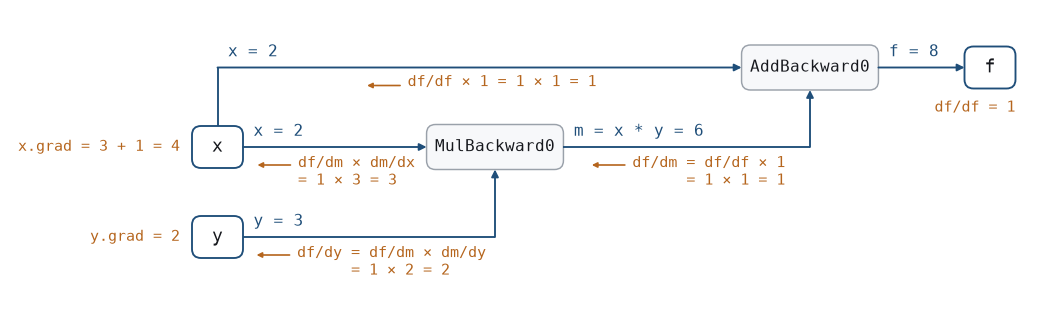

f = x * y + x with x = 2 and y = 3, writing m for x * y. x reaches f through the product, df/dm × dm/dx = 1 × 3 = 3, and directly through the sum, df/df × 1 = 1 × 1 = 1. The sum of the two is x.grad = 4.

Writing `m` for `x * y`, `x` reaches `f` along two paths. The first goes through the product, with the local derivative dm/dx = y = 3. The second goes directly through the sum, with a local derivative of 1. The gradient along the first path is df/dm × dm/dx = 1 × 3 = 3. The gradient along the second is df/df × 1 = 1 × 1 = 1. The two are added before the `AccumulateGrad` node of `x` runs. That node therefore receives 4 in a single call. In symbols, df/dx = y + 1.

### Gradient accumulation

In [ ]:
x = torch.tensor(5.0, requires_grad=True)
(3 * x ** 2 + 4 * x + 2).backward()
(3 * x ** 2 + 4 * x + 2).backward()     # a second pass on a newly built graph
print(x.grad)                           # 34 added to 34

x.grad.zero_()
(3 * x ** 2 + 4 * x + 2).backward()
print(x.grad)

tensor(68.)
tensor(34.)


`backward()` adds into `.grad` instead of overwriting it. The gradients of several losses can then be summed into one tensor. A loop that calls `backward()` once per step therefore resets `.grad` between calls. `zero_()` sets every element to zero in place. The trailing underscore marks every PyTorch method that modifies the tensor it is called on. `backward()` also frees the graph. A second `backward()` on the same result raises a `RuntimeError`. Each pass above therefore computes the expression again.

### One step of gradient descent

In [ ]:
x, y = 2.0, 1.0                                 # one input and its target
w = torch.tensor(-1.0, requires_grad=True)      # weight
b = torch.tensor(5.0, requires_grad=True)       # bias
lr = 0.05                                       # learning rate

for step in range(4):
    pred = w * x + b
    loss = (pred - y) ** 2
    loss.backward()
    print(f"step {step}  prediction {pred.item():.4f}  loss {loss.item():.4f}  "
          f"grad w {w.grad.item():.1f}  grad b {b.grad.item():.1f}")
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()
    b.grad.zero_()

print("w", w.item(), "  b", b.item())

step 0  prediction 3.0000  loss 4.0000  grad w 8.0  grad b 4.0
step 1  prediction 2.0000  loss 1.0000  grad w 4.0  grad b 2.0
step 2  prediction 1.5000  loss 0.2500  grad w 2.0  grad b 1.0
step 3  prediction 1.2500  loss 0.0625  grad w 1.0  grad b 0.5
w -1.75   b 4.625


| step | prediction | loss | `w.grad` | `b.grad` |
|---|---|---|---|---|
| 0 | 3.0 | 4.0 | 8.0 | 4.0 |
| 1 | 2.0 | 1.0 | 4.0 | 2.0 |
| 2 | 1.5 | 0.25 | 2.0 | 1.0 |
| 3 | 1.25 | 0.0625 | 1.0 | 0.5 |

Gradient descent moves every parameter a small step against its gradient. The new value `w - lr * w.grad` replaces `w`. The gradient points in the direction in which the loss increases fastest. A small enough step the other way therefore decreases the loss. Here `dL/dw = 2 * (pred - y) * x` and `dL/db = 2 * (pred - y)`. The first step moves `w` from -1.0 to -1.4 and `b` from 5.0 to 4.8. With this learning rate every step halves the error `pred - y`. The loss therefore falls to a quarter each time. After the four steps `w` is -1.75 and `b` is 4.625.

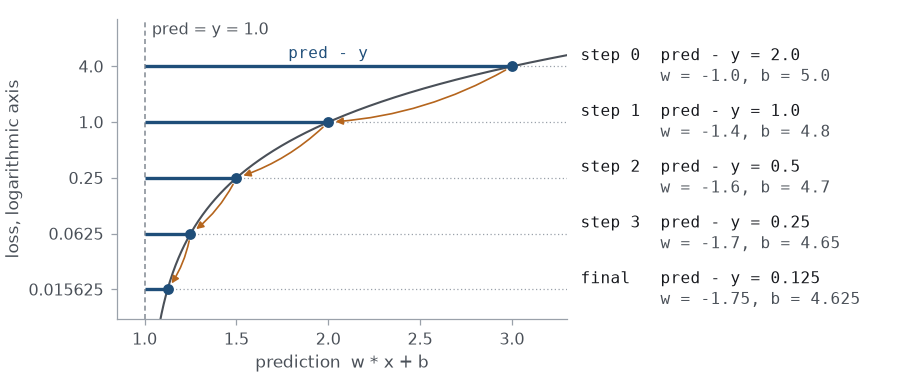

The loss depends on w and b only through the prediction w * x + b. Each step moves the prediction half of the remaining way to y = 1.0. The error pred - y halves at every step, from 2.0 to 0.125. The loss falls to a quarter at every step, the same distance each time on the logarithmic axis.

**Try it.** Run the loop again with `lr = 0.3` and compare the losses.

### torch.no_grad

`torch.no_grad()` stops the recording. The update runs inside it, because the update is not part of the computation being differentiated. Outside it, the in-place `w -= lr * w.grad` raises `RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.` Writing `w = w - lr * w.grad` instead raises no error. It creates a new tensor computed from `w`. The new tensor is not a leaf. The next `backward()` therefore leaves its `.grad` as `None`.

In [ ]:
try:
    w -= lr * w.grad                    # outside torch.no_grad()
except RuntimeError as err:
    print("RuntimeError:", err)

with torch.no_grad():
    pred = w * 3.0 + b
print(pred.requires_grad)

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.
False


The same context manager wraps any computation whose result will not be differentiated, such as predictions on test data. Nothing is recorded. This saves the memory and the time the record takes.

### detach and item

In [ ]:
try:
    w.numpy()
except RuntimeError as err:
    print("RuntimeError:", err)

print(w.detach().numpy())
print(w.item())

RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.
-1.75
-1.75


`detach()` returns a tensor with the same data that is not part of any graph. `.numpy()` accepts the detached tensor. `.item()` returns the value of a one-element tensor as a Python number. A loss is usually printed or stored this way.

`torch.optim.SGD` performs this same update in its `step()` method, for every parameter it was given. Its `zero_grad()` clears every `.grad`, setting it to `None` rather than to zero.

## 03 Neural networks

A neural network is a function from one row of numbers to a prediction, built from weighted sums of its inputs. We compute one in NumPy, from a single unit to a small network, with weights we choose by hand.

### One unit

In [ ]:
x = np.array([57.0, 18581.51, 19.0, 45.8])   # age, income, tenure_months, score
w = np.array([0.02, 0.0001, -0.05, 0.03])    # one weight per input
b = -1.0                                     # the bias

z = x @ w + b
print("products   ", x * w)
print("z          ", round(float(z), 3))
print("ReLU(z)    ", round(float(np.maximum(z, 0.0)), 3))

products    [ 1.14      1.858151 -0.95      1.374   ]
z           2.422
ReLU(z)     2.422


A **unit**, also called a neuron, multiplies each input by its own weight, adds the products and a **bias**, and passes the result through an **activation function**. The most common one is ReLU, `max(z, 0)`. It keeps a positive sum and replaces a negative one with 0. The weights and the bias are the unit's **parameters**: numbers that are set by training rather than written by hand. Here they were written by hand. For income's product to be about as large as the others, income's weight had to be 200 times smaller than age's.

### A layer

In [ ]:
W = np.array([[0.02, 0.0001, -0.05, 0.03],      # (3, 4): one row of weights per unit
              [-0.01, -0.0001, 0.04, 0.01],
              [0.03, 0.00002, 0.02, -0.04]])
bias = np.array([-1.0, 0.5, 0.2])               # one bias per unit

h = np.maximum(W @ x + bias, 0.0)               # (3, 4) @ (4,) + (3,) -> (3,)
print("sums   ", (W @ x + bias).round(3))
print("h      ", h.round(3))

sums    [ 2.422 -0.71   0.83 ]
h       [2.422 0.    0.83 ]


A **layer** is several units that read the same inputs. Its weights form a matrix with one row per unit. One matrix product therefore computes every unit at once. The bias adds one number per unit. The output `h` is a new vector with one number per unit. The next layer reads `h` as its input. A network is a stack of layers. The layers between the input and the output are called **hidden layers**.

### The output

In [ ]:
v = np.array([0.8, -0.6, 0.5])          # the output unit: one weight per unit of the layer
c = -0.2                                # and its bias
p = 1 / (1 + np.exp(-(v @ h + c)))
print("probability", round(float(p), 3))

probability 0.896


For a yes-or-no label, such as whether a customer leaves, the last layer is a single unit whose sum goes through the **sigmoid**, `1 / (1 + exp(-z))`. The sigmoid maps any number to a value between 0 and 1, read as a probability. These weights were chosen by hand. The output 0.896 is therefore not a prediction about this customer. Training sets the weights. For an amount, such as how much a customer spends, the last unit has no activation. Its weighted sum is the prediction.

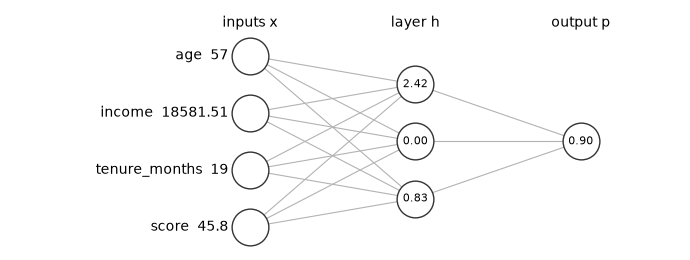

In [ ]:
#@title Figure: the network with the values above  { display-mode: "form" }
fig, ax = plt.subplots(figsize=(7, 2.7))
inputs = ["age  57", "income  18581.51", "tenure_months  19", "score  45.8"]
hidden = [2.422, 0.0, 0.830]
yi, yh, yo = [3.0, 2.0, 1.0, 0.0], [2.5, 1.5, 0.5], 1.5
for a in yi:
    for b in yh:
        ax.plot([0, 1], [a, b], color="0.7", linewidth=0.8, zorder=1)
for b in yh:
    ax.plot([1, 2], [b, yo], color="0.7", linewidth=0.8, zorder=1)
ax.scatter([0] * 4 + [1] * 3 + [2], yi + yh + [yo], s=700, facecolor="white", edgecolor="0.2", zorder=2)
for label, a in zip(inputs, yi):
    ax.text(-0.13, a, label, ha="right", va="center")
for value, b in zip(hidden, yh):
    ax.text(1, b, f"{value:.2f}", ha="center", va="center", fontsize=8)
ax.text(2, yo, "0.90", ha="center", va="center", fontsize=8)
for x, label in [(0, "inputs x"), (1, "layer h"), (2, "output p")]:
    ax.text(x, 3.45, label, ha="center", va="bottom")
ax.set_xlim(-1.45, 2.6)
ax.set_ylim(-0.4, 3.8)
ax.axis("off")
fig.tight_layout()
plt.show()

The network with the values for the customer above: the inputs x, the layer outputs h = max(W @ x + bias, 0), and the output p after the sigmoid, 0.896. Every line is one weight: 12 between the inputs and the layer, the rows of W, and 3 between the layer and the output, the entries of v.

In [ ]:
X = np.array([[57.0, 18581.51, 19.0, 45.8],     # (2, 4): two customers, one per row
              [48.0, 35917.79, 15.0, 58.6]])
print(np.maximum(X @ W.T + bias, 0.0).round(3))  # (2, 4) @ (4, 3) + (3,) -> (2, 3)

[[2.422 0.    0.83 ]
 [4.56  0.    0.314]]


A whole table goes through the network the same way. With one customer per row of `X`, `X @ W.T` computes every unit for every customer in one product. The bias broadcasts across the rows. This is why the input of a network is a matrix: one row per example, one column per input.

### Training

The weights start as random numbers. Training passes rows whose label is known through the network, measures how far its predictions are from the labels with a **loss**, a single number averaged over the rows, and moves every weight a small step in the direction that lowers the loss. That direction comes from the **gradient**, the derivative of the loss with respect to each weight. The derivative of a weighted sum with respect to one weight is the input that weight multiplies. The step a weight takes is therefore proportional to its input. For the customer above, in the same unit, the step for income's weight is 406 times the step for score's.

## 04 Linear regression

We fit a straight line, `w * x + b`, to 200 points by gradient descent on the mean squared error between its predictions and the targets, once by hand with tensors and autograd and once with `nn.Linear`, `nn.MSELoss` and `torch.optim.SGD`. The code below generates the points by adding noise to a curve. A straight line can therefore follow their overall rise but not their bends.

In [ ]:
rng = np.random.default_rng(0)
x = rng.uniform(-3, 3, 200)
y = np.sin(1.5 * x) + 0.3 * x + rng.normal(0, 0.15, 200)   # a curve plus noise

X = torch.tensor(x, dtype=torch.float32).reshape(-1, 1)    # (200,) -> (200, 1)
Y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
X.shape

torch.Size([200, 1])

The inputs of a model form a matrix with one row per example and one column per input, here a single column. `reshape(-1, 1)` gives one column and as many rows as the data fills. The targets get the same shape, `(200, 1)`, as the loss below requires. Both are float32, the dtype of the parameters of a PyTorch layer.

### The line by hand

In [ ]:
w = torch.zeros(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

for step in range(100):
    pred = X * w + b                        # (200, 1) * (1,) + (1,) -> (200, 1)
    loss = ((pred - Y) ** 2).mean()         # the mean squared error
    loss.backward()
    with torch.no_grad():
        w -= 0.1 * w.grad
        b -= 0.1 * b.grad
    w.grad.zero_()
    b.grad.zero_()

print(round(w.item(), 4), round(b.item(), 4))
print(round(loss.item(), 4))
print(np.polyfit(x, y, 1).round(4))         # the same line, solved directly

0.2381 -0.0174
0.5256
[ 0.2381 -0.0174]


The loop repeats one step of gradient descent 100 times over all 200 points. The loss is the **mean squared error**, the mean of `(pred - Y) ** 2` over the rows. Every point therefore contributes to both gradients. After 100 steps the weight is 0.2381 and the bias -0.0174. This is the **least-squares line**, the line with the smallest mean squared error. `np.polyfit(x, y, 1)` computes it directly and returns the same two numbers.

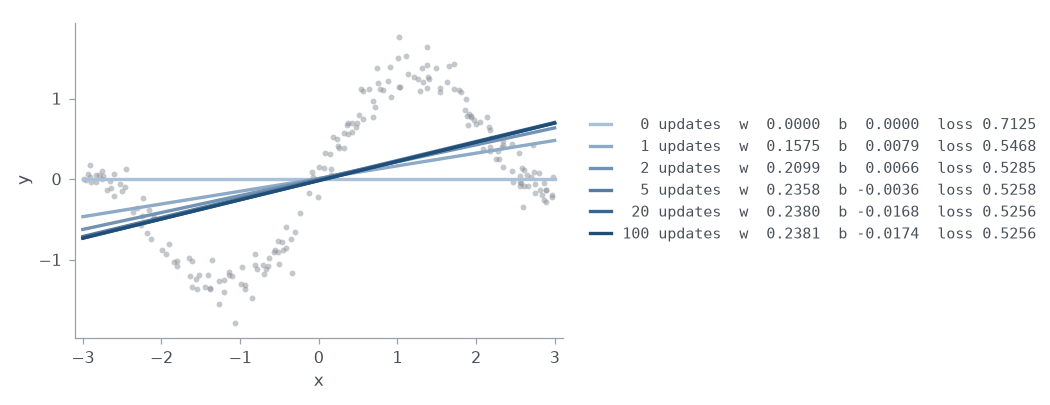

The line after 0, 1, 2, 5, 20 and 100 updates of the loop above, darker as the updates go on. The first update removes most of the loss. After 20 updates the line is within a thousandth of the least-squares line. Its loss no longer changes in the fourth decimal.

### nn.Linear, nn.MSELoss and torch.optim.SGD

In [ ]:
torch.manual_seed(0)
line = nn.Linear(1, 1)                      # weight (1, 1), bias (1,)
loss_fn = nn.MSELoss()
opt = torch.optim.SGD(line.parameters(), lr=0.1)

for step in range(100):
    loss = loss_fn(line(X), Y)
    opt.zero_grad()                         # every .grad to None
    loss.backward()
    opt.step()                              # every parameter minus lr times its gradient

round(line.weight.item(), 4), round(line.bias.item(), 4)

(0.2381, -0.0174)

The code above is the same model and the same loop, written with three PyTorch objects. `nn.Linear(1, 1)` holds a weight and a bias as tensors with `requires_grad=True`, starting from random values. `line(X)` computes `X @ line.weight.T + line.bias`. `nn.MSELoss()` returns a function that computes the mean squared error of its two arguments. `torch.optim.SGD` holds the parameters it is given and the learning rate. `opt.zero_grad()` sets the `.grad` of every parameter to `None`. `opt.step()` subtracts `lr` times its gradient from every parameter, the update that the hand-written loop writes out. Inside the loop, `opt.zero_grad()` runs before `loss.backward()`. `opt.step()` runs last. `torch.manual_seed(0)` fixes the random starting values. A run can therefore be repeated.

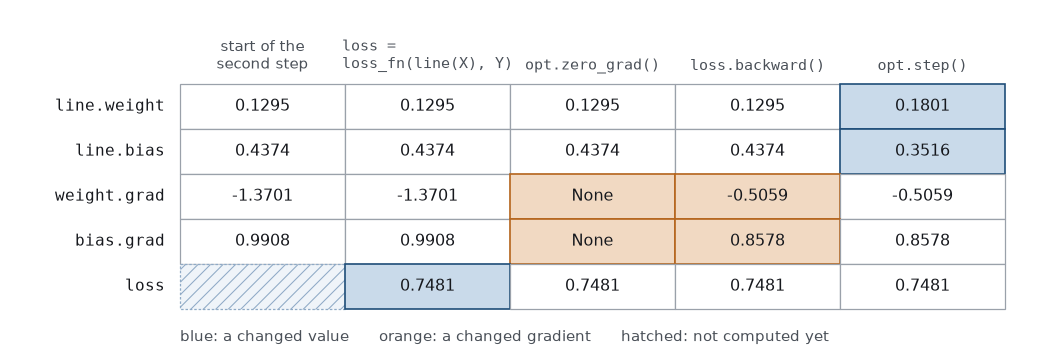

The second step of the loop above, one column per statement. opt.zero_grad() sets the gradients left by the first step to None. loss.backward() computes the new ones. opt.step() subtracts 0.1 times each from its parameter, for example 0.1295 - 0.1 × -0.5059 = 0.1801.

`nn.Linear` started from a weight of -0.0075 and a bias of 0.5364. The hand-written loop started from zeros. Both end at the same line. The mean squared error of a straight line has a single minimum. With this learning rate, 100 steps reach it.

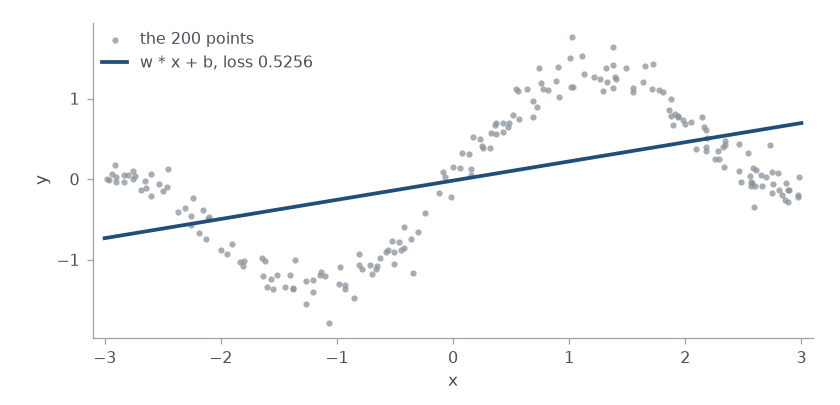

The 200 points and the least-squares line, weight 0.2381 and bias -0.0174. Its loss is 0.5256, against 0.7109 for the flat line at the mean of y. The line follows the overall rise of the points and none of their bends.

## 05 nn.Module

A network is an object that holds its parameters and applies them in a method. We write it as an ordinary class that inherits from `nn.Module`. We create the layers, and with them the parameters, in `__init__`. We write the computation from the input to the output in `forward`.

In [ ]:
class Net(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()                  # required, before anything else
        self.stack = nn.Sequential(
            nn.Linear(n_in, n_hidden), nn.ReLU(),
            nn.Linear(n_hidden, 1))

    def forward(self, x):                   # (n, n_in) -> (n, 1)
        return self.stack(x)

torch.manual_seed(0)
net = Net(1, 16)
net(X).shape                                # calls forward and the hooks around it

torch.Size([200, 1])

`super().__init__()` runs `nn.Module`'s setup. The setup creates the dictionaries that hold the module's layers and parameters. Without it, assigning a layer to `self` raises `AttributeError: cannot assign module before Module.__init__() call`. Layers are assigned to `self`. The assignment registers them with the module. `forward` defines the computation. The object is called, `net(X)`, rather than `net.forward(X)`, because `nn.Module.__call__` runs the registered hooks before and after `forward`.

### nn.Linear and nn.ReLU

In [ ]:
lin = nn.Linear(1, 16)
print(lin.weight.shape)                     # (out, in), not (in, out)
print(lin.bias.shape)
print(lin(torch.zeros(5, 1)).shape)         # the last axis is transformed

torch.Size([16, 1])
torch.Size([16])
torch.Size([5, 16])


`nn.Linear(a, b)` is a layer of `b` units reading `a` inputs. It computes `x @ W.T + bias`. Every row of the input becomes a row of `b` numbers. `nn.ReLU()` applies `max(x, 0)` elementwise and has no parameters. `nn.Sequential` calls what it holds in order. `Net(1, 16)` is one input, a hidden layer of 16 units with ReLU, and one output unit with no activation, the form a prediction of an amount takes.

### Parameter count

In [ ]:
print(sum(p.numel() for p in net.parameters()))

[(name, tuple(p.shape)) for name, p in net.named_parameters()]

49


[('stack.0.weight', (16, 1)),
 ('stack.0.bias', (16,)),
 ('stack.2.weight', (1, 16)),
 ('stack.2.bias', (1,))]

The parameters are 16 by 1 plus 16, then 1 by 16 plus 1, 49 numbers in all. Training adjusts every one of them. `parameters()` is what an optimizer is given. The indices skip 1 because `nn.Sequential` numbers the activation too.

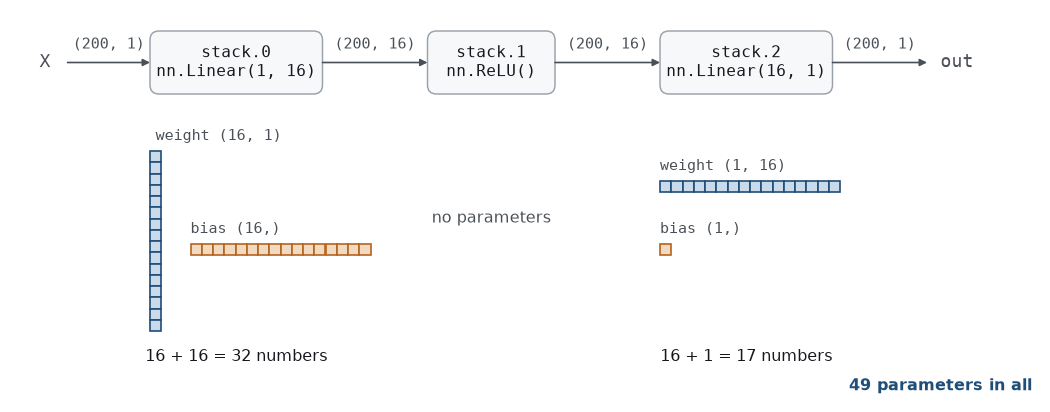

Net(1, 16) applied to X: the shape of what each layer returns, and the parameters each layer holds, one cell per number. Each nn.Linear holds a weight of shape (out, in) and a bias of shape (out,). nn.ReLU holds none.

### Layers as attributes

In [ ]:
class Net2(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        self.hidden = nn.Linear(n_in, n_hidden)
        self.out = nn.Linear(n_hidden, 1)

    def forward(self, x):
        return self.out(torch.relu(self.hidden(x)))   # ReLU, called as a function

[name for name, p in Net2(1, 16).named_parameters()]

['hidden.weight', 'hidden.bias', 'out.weight', 'out.bias']

The code above defines the same network without `nn.Sequential`. Assigning every layer that has parameters to an attribute registers it. `forward` states the order explicitly. ReLU has no parameters to register. It can therefore be called as a function. `torch.relu` computes the same as `nn.ReLU()`, as does `torch.nn.functional.relu`. The parameter count is the same 49. Only the names change. This form is needed as soon as `forward` does more than apply layers in a fixed order, for example when it uses one input in two places.

## 06 An MLP on a curve

A network with one or more hidden layers between its input and its output is a **multilayer perceptron**, an MLP. We train `Net(1, 16)` on the same 200 points with the same loop. It follows the bends that the straight line misses. To see where the bends come from, we look at the share of each of its 16 hidden units in the prediction.

In [ ]:
torch.manual_seed(0)
net = Net(1, 16)
opt = torch.optim.SGD(net.parameters(), lr=0.05)

losses = []
for step in range(3000):
    loss = loss_fn(net(X), Y)
    losses.append(loss.item())
    opt.zero_grad()
    loss.backward()
    opt.step()

round(losses[0], 4), round(losses[-1], 4)

(0.6393, 0.0254)

The loss falls from 0.6393 to 0.0254, against 0.5256 for the line. The noise added to the points has a standard deviation of 0.15. Even the curve the points were drawn from therefore has a loss of 0.0238 on them. The MLP ends 0.0016 above it. Most of the descent happens early. The loss is 0.0293 at step 500, 0.0265 at step 1000 and 0.0256 at step 2000.

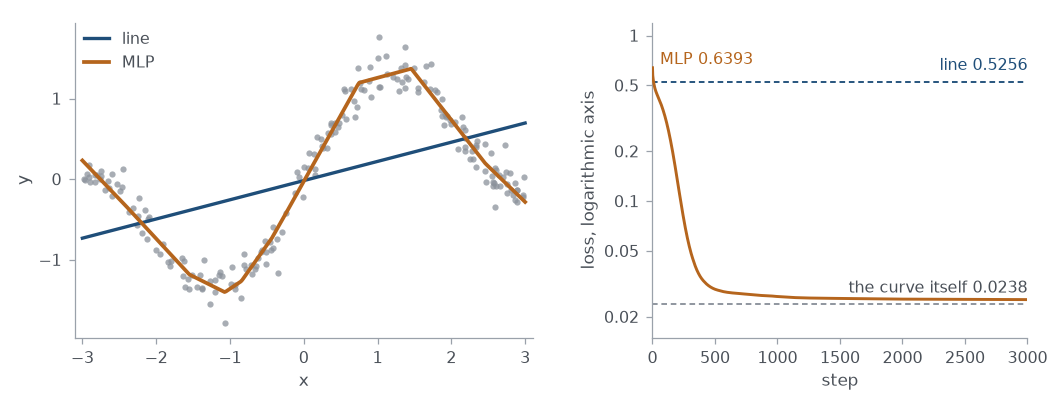

Left: the 200 points with the line and the MLP after training. Right: the MLP's loss at each of its 3000 steps on a logarithmic axis, with the line's loss and the loss of the curve the points were drawn from as references.

**Try it.** Train `Net(1, 4)` and `Net(1, 64)` with the same loop and compare their final losses with 0.0254.

### The hidden units

In [ ]:
w1 = net.stack[0].weight.detach().reshape(-1)    # (16, 1) -> (16,)   hidden weights
b1 = net.stack[0].bias.detach()                  # (16,)
v = net.stack[2].weight.detach().reshape(-1)     # (1, 16) -> (16,)   output weights
c = net.stack[2].bias.detach()                   # (1,)

grid = torch.linspace(-3, 3, 7)
units = torch.relu(grid[:, None] * w1 + b1) * v  # (7, 1) * (16,) -> (7, 16)
torch.allclose(units.sum(axis=1) + c, net(grid[:, None]).reshape(-1))

True

Each hidden unit computes `relu(w * x + b)` of the single input: zero on one side of x = -b / w and a straight line on the other, a hinge. The output multiplies each hinge by its weight in `v`, adds them and adds `c`. `torch.allclose` confirms this on seven points. The network's prediction is therefore a sum of 16 hinges, a broken line that bends wherever one of them does. Training moves the bends and changes the slopes. `.detach()` returns the parameters as tensors outside the recorded graph, since nothing here is differentiated.

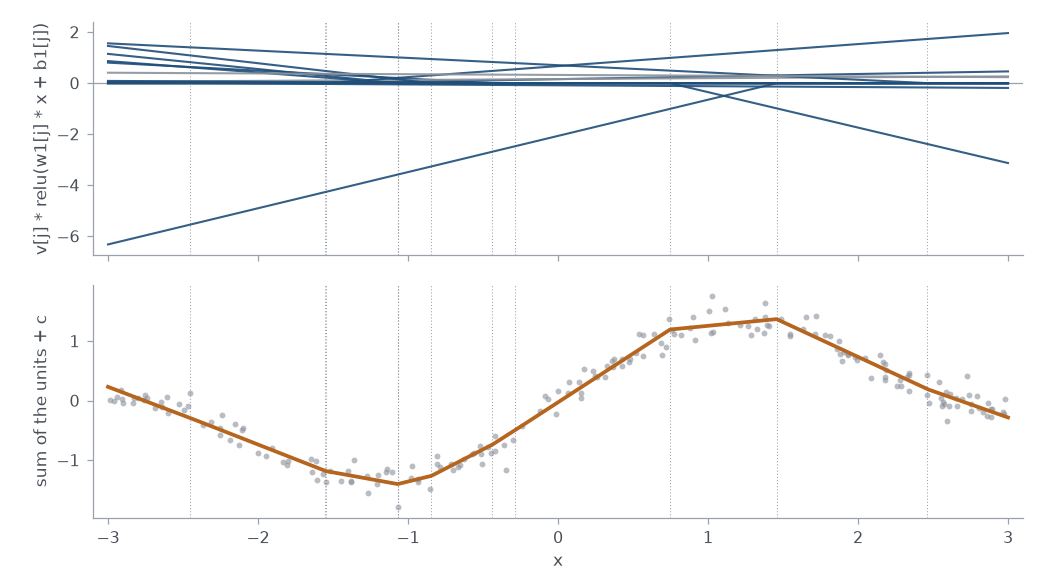

Top: each hidden unit's share of the output over the range of the points. The 12 units drawn in blue bend inside the range, at the dotted lines. The 2 in grey are straight over the whole range. The 2 units that are zero everywhere on it are not drawn. Bottom: their sum plus c, the network's prediction, a broken line that bends at the same places.

### Without the activation

In [ ]:
torch.manual_seed(0)
flat = nn.Sequential(nn.Linear(1, 16), nn.Linear(16, 1))   # no activation between the layers
opt = torch.optim.SGD(flat.parameters(), lr=0.05)
for step in range(3000):
    loss = loss_fn(flat(X), Y)
    opt.zero_grad()
    loss.backward()
    opt.step()

round(loss.item(), 4)                       # the straight line's loss

0.5256

Two linear layers in a row compute `W2 @ (W1 @ x + b1) + b2`. This equals `(W2 @ W1) @ x + (W2 @ b1 + b2)`, one weight and one bias. The result is a straight line again. With 16 units and 49 parameters this network ends at the line's loss, 0.5256. The bends come from the activation between the layers.

## 07 Regression on the register

We use the customer register to predict `spend`, the amount a customer spent, from `tenure_months`, `score` and `income`, with a line and with an MLP. The register marks every row as `train` or `test` in its `split` column. We train both models on the training rows only and measure them on the test rows, customers that neither model was trained on.

In [ ]:
def read_rows(path):
    with open(path, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))        # one dictionary per row, every value a string

def column(name):                             # one numeric column, missing values as NaN
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in records])

records = read_rows("register.csv")
tenure, score = column("tenure_months"), column("score")
income, spend = column("income"), column("spend")
split = np.array([r["split"] for r in records])       # "train" or "test" for every row
plan = np.array([r["plan"] for r in records])         # the customer's plan, as text
print(len(records))

9000


`csv.DictReader` reads the first line of the file as the column names. It returns each remaining line as a dictionary from column name to text. `column` turns an empty field into NaN.

In [ ]:
F = np.stack([tenure, score, income], axis=1)            # (9000, 3)
present = ~np.isnan(F).any(axis=1)                       # score and income have gaps
train = present & (split == "train")
test = present & (split == "test")
print(int(train.sum()), int(test.sum()))

mean, std = F[train].mean(axis=0), F[train].std(axis=0)  # from the training rows only
Xtr = torch.tensor((F[train] - mean) / std, dtype=torch.float32)
Xte = torch.tensor((F[test] - mean) / std, dtype=torch.float32)
ytr = torch.tensor(spend[train] / 1000, dtype=torch.float32).reshape(-1, 1)   # in thousands
yte = torch.tensor(spend[test] / 1000, dtype=torch.float32).reshape(-1, 1)

5933 1962


The features are standardised with the mean and the standard deviation of the training rows. The test rows are scaled with the same two numbers. Nothing about the test rows therefore reaches the model before it is measured. The target is divided by 1000. Its values then lie around 1, the scale of the curve's targets.

In [ ]:
def fit(model, X, Y, lr, steps):
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    for step in range(steps):
        loss = loss_fn(model(X), Y)
        opt.zero_grad()
        loss.backward()
        opt.step()

torch.manual_seed(0)
line = nn.Linear(3, 1)
fit(line, Xtr, ytr, lr=0.1, steps=200)
mlp = Net(3, 16)
fit(mlp, Xtr, ytr, lr=0.1, steps=1000)

### RMSE and MAE

In [ ]:
def rmse(pred, target):
    return ((pred - target) ** 2).mean().sqrt().item() * 1000    # in units of spend

def mae(pred, target):
    return (pred - target).abs().mean().item() * 1000

with torch.no_grad():
    mean_pred = torch.full_like(yte, ytr.mean().item())   # the training mean on every row
    for name, pred in [("mean", mean_pred), ("line", line(Xte)), ("MLP", mlp(Xte))]:
        print(f"{name:<5} RMSE {rmse(pred, yte):6.1f}   MAE {mae(pred, yte):6.1f}")

mean  RMSE  544.3   MAE  427.4
line  RMSE  256.0   MAE  203.2
MLP   RMSE  253.4   MAE  201.3


The error is reported in the unit of the target rather than its square. **Root mean squared error**, RMSE, is the square root of the mean squared error. **Mean absolute error**, MAE, is the mean of `abs(pred - target)`. MAE is less affected by a few large errors than RMSE. Either is quoted beside the error of predicting the mean of the training targets for every row. For RMSE that baseline is close to the standard deviation of the target. Here it is 544.3, against 256.0 for the line. The MLP is 1 per cent better than the line, 253.4 against 256.0. On these three columns a hidden layer adds little to a straight line.

### A fourth column

In [ ]:
plans = ["basic", "standard", "premium", "legacy"]
onehot = np.stack([(plan == p).astype(np.float32) for p in plans], axis=1)   # (9000, 4)
Xtr4 = torch.cat([Xtr, torch.tensor(onehot[train])], axis=1)              # (5933, 7)
Xte4 = torch.cat([Xte, torch.tensor(onehot[test])], axis=1)

torch.manual_seed(0)
line4 = nn.Linear(7, 1)
fit(line4, Xtr4, ytr, lr=0.1, steps=500)
with torch.no_grad():
    print(round(rmse(line4(Xte4), yte), 1))

209.1


The plan, one-hot encoded, lowers the line's RMSE from 256.0 to 209.1. The MLP on the three columns reached 253.4. `torch.cat` joins tensors along an existing axis, here the columns, like `np.concatenate`.

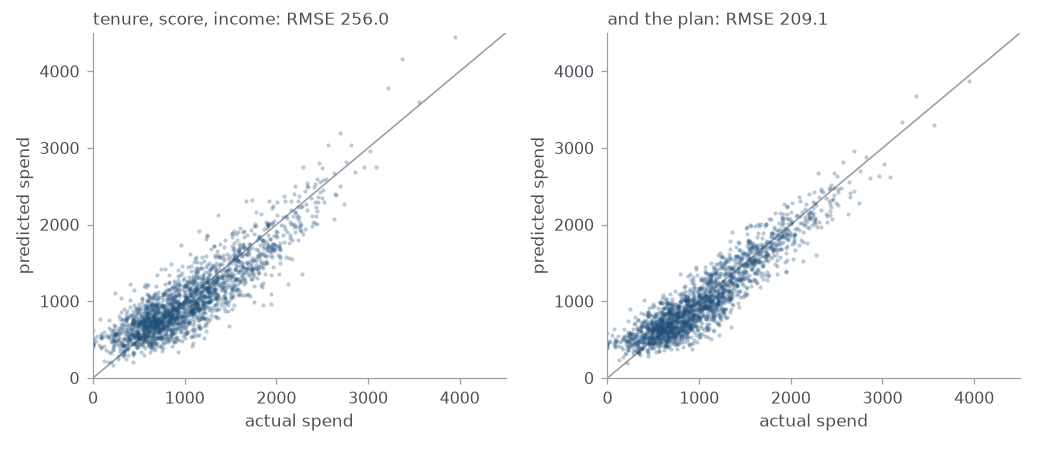

Predicted against actual spend for the 1962 test rows, one point per row, with the diagonal where the two are equal. Left: the line on tenure_months, score and income. Right: the same line with the plan added as four one-hot columns. Its points lie closer to the diagonal.

**Try it.** Train `Net(7, 16)` on `Xtr4` with `fit(..., lr=0.1, steps=1000)` and compare its RMSE with the line's 209.1.

### Mismatched target shape

In [ ]:
nn.MSELoss()(torch.zeros(8, 1), torch.zeros(8))   # prints a UserWarning

/home/tamas/miniconda3/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([8])) that is different to the input size (torch.Size([8, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


tensor(0.)

A prediction of shape `(8, 1)` against a target of shape `(8,)` broadcasts to `(8, 8)` and averages 64 differences instead of 8. PyTorch only warns. The loss is still computed and returned.

In [ ]:
torch.manual_seed(0)
line = nn.Linear(1, 1)
opt = torch.optim.SGD(line.parameters(), lr=0.1)
for step in range(100):
    loss = loss_fn(line(X), Y.reshape(-1))  # prediction (200, 1), target (200,)
    opt.zero_grad()
    loss.backward()
    opt.step()

print(round(line.bias.item(), 4), round(loss.item(), 4))
print(round(y.mean(), 4), round(y.var(), 4))

0.0393 0.7109
0.0393 0.7109


/home/tamas/miniconda3/lib/python3.14/site-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([200])) that is different to the input size (torch.Size([200, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


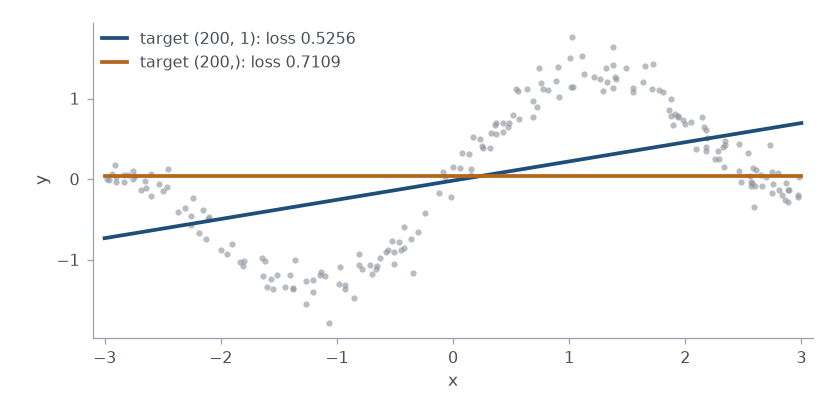

The same line trained twice on the 200 points. With the target of shape (200, 1) it ends at the least-squares line. With the target of shape (200,) the loss averages over all 200 × 200 pairs of prediction and target. The line then ends flat at the mean of y, 0.0393.

With a target of shape `(200,)`, the loss averages the squared difference between every prediction and every one of the 200 targets. That average is smallest when every prediction equals the mean of `y`. The weight goes to zero. The bias goes to 0.0393, the mean of `y`. The loss ends at 0.7109, the variance of `y`. Every target above has the shape `(n, 1)` of the predictions. That shape prevents the mismatch.

### Further reading

- [torch.Tensor](https://docs.pytorch.org/docs/stable/tensors.html), for the dtypes and every tensor method.
- [A Gentle Introduction to torch.autograd](https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html), and [Autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html) for leaves, `grad_fn` and no-grad mode.
- [Build the Neural Network](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html) and [Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html), the two PyTorch tutorials on `nn.Module` and the training loop.
- [nn.Module](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html), [nn.Linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html), [nn.Sequential](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html) and [nn.MSELoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html).
- [torch.optim](https://docs.pytorch.org/docs/stable/optim.html), for the other optimizers and their arguments.